# Chapter 7: Unsupervised Learning
**Practical Statistics for Data Scientists (2nd Edition)** — Peter Bruce, Andrew Bruce & Peter Gedeck (O'Reilly)

Notebook ini berisi **reproduksi kode** dan **penjelasan teori** dari Chapter 7. Data yang dipakai adalah harga saham S&P 500 (`sp500_data.csv.gz`), data pinjaman LendingClub (`loan_data.csv.gz`), dan data pembagian tugas rumah tangga (`housetasks.csv`).

## Ringkasan Chapter
*Unsupervised learning* adalah kumpulan metode statistik yang mengekstrak makna dari data **tanpa melatih model pada data berlabel**, yaitu data yang hasil (*outcome*) yang diminati tidak diketahui. Pada Chapter 4 sampai 6, tujuannya membangun model untuk memprediksi sebuah variabel respons dari sejumlah variabel prediktor (*supervised learning*). Pada *unsupervised learning*, model tetap dibangun, tetapi **tidak ada pembedaan antara variabel respons dan variabel prediktor**.

Metode ini dipakai untuk beberapa tujuan:
1. **Membuat aturan prediksi tanpa respons berlabel.** Contoh: dari data klik dan demografi pengguna situs web, kita mengelompokkan pengguna ke dalam beberapa tipe, lalu menyesuaikan tampilan situs untuk tiap tipe.
2. **Mereduksi dimensi data** menjadi sekumpulan variabel yang lebih ringkas. Contoh: ribuan sensor pada proses industri diringkas menjadi beberapa fitur, sehingga model prediksi kegagalan menjadi lebih kuat dan lebih mudah ditafsirkan.
3. **Memperluas analisis data eksploratif (EDA, Chapter 1)** ketika variabel dan record sangat banyak, untuk menemukan hubungan antarvariabel.

> **Unsupervised learning dan prediksi.** Pengelompokan (*clustering*) sangat berguna untuk **masalah *cold-start***: situasi ketika kita belum memiliki data respons untuk melatih model, misalnya saat meluncurkan kampanye pemasaran baru atau mencari jenis penipuan baru. Dengan *clustering*, kita bisa langsung mengidentifikasi segmen populasi, lalu seiring bertambahnya data, membangun model prediksi biasa. *Clustering* juga membantu ketika suatu subpopulasi kecil tidak terwakili dengan baik dalam data keseluruhan: subpopulasi itu dapat diberi label, dilatih dengan model tersendiri, atau dijadikan fitur tersendiri.

Bagian-bagian chapter ini:

| Bagian | Inti |
|---|---|
| Principal Components Analysis (PCA) | Meringkas banyak variabel numerik menjadi sedikit komponen yang menjelaskan sebagian besar variasi |
| Correspondence Analysis | "PCA" untuk data kategorikal, dipakai untuk visualisasi |
| K-Means Clustering | Membagi data menjadi K kelompok dengan meminimalkan jarak ke rata-rata kelompok |
| Hierarchical Clustering | Menggabungkan record secara bertahap menjadi pohon pengelompokan (dendrogram) |
| Model-Based Clustering | Pengelompokan berbasis campuran distribusi normal multivariat |
| Scaling and Categorical Variables | Penskalaan variabel dan jarak Gower untuk data campuran |

## 0. Setup dan Persiapan Data

| File | Isi |
|---|---|
| `sp500_data.csv.gz` | Return harian saham-saham S&P 500 (tiap kolom satu saham, tiap baris satu hari perdagangan) |
| `loan_data.csv.gz` | 45.342 pinjaman LendingClub (data seimbang: 50% *default*, 50% *paid off*) |
| `housetasks.csv` | Tabel jumlah pasangan yang mengerjakan 13 jenis tugas rumah tangga (istri, bergantian, suami, bersama) |

> **Catatan versi library.** Buku memakai `prince.CA(...).plot_coordinates(...)` untuk menggambar *biplot*. Metode itu sudah tidak ada pada `prince` versi terbaru, sehingga *biplot* digambar sendiri dengan `matplotlib` dari koordinat baris dan kolom hasil `prince`. Konsep dan hasil analisisnya sama.

In [1]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns

from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform

from sklearn import preprocessing
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

import prince

%matplotlib inline
pd.set_option('display.width', 120)

DATA = Path('data')
SP500_DATA_CSV = DATA / 'sp500_data.csv.gz'
LOAN_DATA_CSV = DATA / 'loan_data.csv.gz'
HOUSE_TASKS_CSV = DATA / 'housetasks.csv'

In [2]:
sp500_px = pd.read_csv(SP500_DATA_CSV, index_col=0)

loan_data = pd.read_csv(LOAN_DATA_CSV)
loan_data = loan_data.drop(columns=['Unnamed: 0', 'status'], errors='ignore')
for col in ['outcome', 'purpose_', 'home_', 'emp_len_']:
    loan_data[col] = loan_data[col].astype('category')

housetasks = pd.read_csv(HOUSE_TASKS_CSV, index_col=0)

print('sp500_px  :', sp500_px.shape, '| periode', sp500_px.index[0], 'sampai', sp500_px.index[-1])
print('loan_data :', loan_data.shape)
print('housetasks:', housetasks.shape)
sp500_px.iloc[:3, :6]

sp500_px  : (5647, 517) | periode 1993-01-29 sampai 2015-07-01
loan_data : (45342, 19)
housetasks: (13, 4)


,ADS,CA,MSFT,RHT,CTSH,CSC
1993-01-29,0.0,0.060124,-0.022100,0.0,0.0,0.018897
1993-02-01,0.0,-0.180389,0.027621,0.0,0.0,0.018889
1993-02-02,0.0,-0.120257,0.035900,0.0,0.0,-0.075573


---
## 1. Principal Components Analysis (PCA)

### Teori

Sering kali variabel-variabel **bervariasi bersama** (*covary*), dan sebagian variasi pada satu variabel sebenarnya sudah terwakili oleh variasi pada variabel lain. Contoh sederhana: **total tagihan restoran dan tip**. Semakin besar tagihan, semakin besar pula tip, sehingga keduanya membawa informasi yang tumpang tindih. *Principal Components Analysis* (PCA) adalah teknik untuk menemukan cara variabel-variabel numerik bervariasi bersama. PCA pertama kali diusulkan oleh Karl Pearson dan dapat dipandang sebagai versi *unsupervised* dari *Linear Discriminant Analysis* (Chapter 5).

**Istilah kunci**
- **Principal component (komponen utama):** kombinasi linear dari variabel-variabel prediktor.
- **Loadings (bobot):** bobot yang mengubah variabel asli menjadi komponen.
- **Screeplot:** grafik varians tiap komponen, yang menunjukkan kepentingan relatif komponen (sebagai varians yang dijelaskan atau proporsinya).

**Gagasan inti.** PCA menggabungkan beberapa variabel numerik menjadi himpunan variabel yang lebih kecil, yaitu kombinasi linear berbobot dari variabel asli. Himpunan kecil ini (komponen utama) "menjelaskan" sebagian besar variabilitas seluruh variabel, sehingga dimensi data berkurang. Bobot yang dipakai membentuk komponen memperlihatkan kontribusi relatif tiap variabel asli.

**Contoh dua variabel.** Untuk dua variabel $X_1$ dan $X_2$ terdapat dua komponen utama $Z_i$ ($i = 1$ atau $2$):

$$Z_i = w_{i,1}X_1 + w_{i,2}X_2$$

Bobot $w_{i,1}, w_{i,2}$ disebut *component loadings*. Komponen pertama $Z_1$ adalah kombinasi linear yang **paling banyak menjelaskan variasi total**. Komponen kedua $Z_2$ **tegak lurus (ortogonal)** terhadap yang pertama dan menjelaskan sebanyak mungkin sisa variasi. Jika ada komponen tambahan, masing-masing ortogonal terhadap semua komponen sebelumnya.

> PCA umumnya dihitung pada **deviasi dari rata-rata** variabel, bukan pada nilai variabelnya langsung (`scikit-learn` melakukan pemusatan ini secara otomatis).

### Kode: PCA untuk return saham Chevron (CVX) dan ExxonMobil (XOM)

In [3]:
oil_px = sp500_px[['CVX', 'XOM']]

pcs = PCA(n_components=2)
pcs.fit(oil_px)
loadings = pd.DataFrame(pcs.components_, columns=oil_px.columns,
                        index=['PC1', 'PC2'])
loadings

,CVX,XOM
PC1,0.747101,0.664711
PC2,-0.664711,0.747101


Bobot untuk CVX dan XOM pada komponen pertama sama-sama berbobot sama tanda dan hampir sama besar, sedangkan komponen kedua memiliki tanda yang berlawanan. Cara membacanya: komponen pertama pada dasarnya adalah **rata-rata** CVX dan XOM, mencerminkan korelasi kedua perusahaan energi. Komponen kedua mengukur **saat harga kedua saham itu berbeda arah** (diverge).

> **Catatan tanda.** Membalik tanda semua bobot pada suatu komponen tidak mengubah komponen tersebut. Garis tak hingga yang ditentukan oleh titik asal dan $(1, 1)$ sama dengan garis yang ditentukan oleh titik asal dan $(-1, -1)$. Karena itu bobot pada buku (−0,747 dan −0,665 dari R) dan hasil Python (positif) setara.

Berikut visualisasi komponen utama bersama data (Figure 7-1). Garis putus-putus menunjukkan arah kedua komponen: yang pertama sepanjang **sumbu panjang** elips data, yang kedua sepanjang **sumbu pendek**.

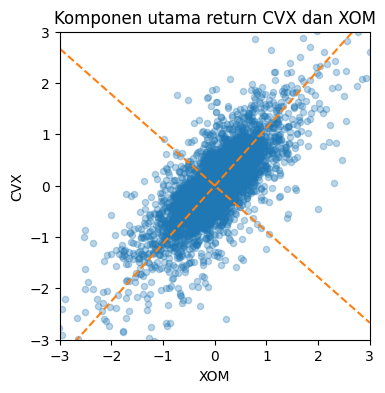

In [4]:
def abline(slope, intercept, ax):
    # Hitung koordinat garis berdasarkan kemiringan dan intersep
    x_vals = np.array(ax.get_xlim())
    return (x_vals, intercept + slope * x_vals)

ax = oil_px.plot.scatter(x='XOM', y='CVX', alpha=0.3, figsize=(4, 4))
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.plot(*abline(loadings.loc['PC1', 'CVX'] / loadings.loc['PC1', 'XOM'], 0, ax),
        '--', color='C1')
ax.plot(*abline(loadings.loc['PC2', 'CVX'] / loadings.loc['PC2', 'XOM'], 0, ax),
        '--', color='C1')
ax.set_title('Komponen utama return CVX dan XOM')
plt.show()

**Interpretasi hasil:**
- Bobot komponen pertama adalah 0,747 (CVX) dan 0,665 (XOM): keduanya berbobot positif dan hampir sama besar, sehingga PC1 pada dasarnya adalah **rata-rata** return kedua saham energi. Bobot komponen kedua berlawanan tanda (−0,665 dan 0,747), sehingga PC2 mengukur **selisih** gerak keduanya. Nilainya sama dengan buku (−0,747 dan −0,665 dari R); perbedaan tanda tidak berpengaruh.
- Pada plot, awan titik berbentuk elips miring ke kanan atas. Garis putus-putus pertama berada di sepanjang **sumbu panjang** elips (arah keduanya naik atau turun bersamaan), sedangkan garis kedua tegak lurus di sepanjang sumbu pendek.
- Sebagian besar variabilitas terjelaskan oleh komponen pertama. Hal ini masuk akal karena harga saham sektor energi cenderung bergerak sebagai satu kelompok.

### Teori: Menghitung komponen utama

Berpindah dari dua variabel ke banyak variabel itu mudah. Untuk komponen pertama, seluruh variabel prediktor tambahan disertakan dalam kombinasi linear, dengan bobot yang dioptimalkan agar menangkap kovariasi dari semua variabel. Perhitungan komponen utama adalah metode statistik klasik yang memakai **matriks korelasi atau matriks kovarians** data, dan berjalan cepat karena **tidak bergantung pada iterasi**. PCA hanya bekerja pada variabel **numerik**, bukan kategorikal.

Prosesnya:
1. Komponen pertama dibuat dari kombinasi linear variabel yang **memaksimalkan persentase varians total yang dijelaskan**.
2. Kombinasi linear ini menjadi prediktor "baru" pertama, $Z_1$.
3. PCA mengulangi proses dengan variabel yang sama dan bobot berbeda untuk membuat prediktor baru kedua, $Z_2$, dengan syarat $Z_1$ dan $Z_2$ **tidak berkorelasi**.
4. Proses berlanjut sampai jumlah komponen sama dengan jumlah variabel asli.
5. Pertahankan komponen sebanyak yang dibutuhkan untuk menjelaskan sebagian besar varians.
6. Terakhir, data asli diubah menjadi **skor komponen utama** dengan menerapkan bobot pada nilai asli. Skor inilah yang dipakai sebagai himpunan prediktor yang lebih ringkas.

### Tambahan: verifikasi manual lewat dekomposisi matriks kovarians
Bagian ini **tidak ada di buku**. Tujuannya menunjukkan bahwa komponen utama tidak lain adalah *eigenvector* matriks kovarians, dan varians tiap komponen adalah *eigenvalue*-nya.

In [5]:
# 1) matriks kovarians dari data yang sudah dipusatkan
cov = np.cov(oil_px.values, rowvar=False)
print('matriks kovarians:'); print(pd.DataFrame(cov, index=['CVX', 'XOM'], columns=['CVX', 'XOM']).round(4))

# 2) eigenvalue dan eigenvector (urutkan dari terbesar)
eigvals, eigvecs = np.linalg.eigh(cov)
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]
print('\neigenvalue (varians tiap komponen):', eigvals.round(4))
print('varians komponen dari sklearn     :', pcs.explained_variance_.round(4))

# 3) skor komponen: pusatkan data, lalu kalikan dengan bobot
scores = pcs.transform(oil_px)
print('\nkorelasi antar skor komponen (harus mendekati 0):')
print(np.corrcoef(scores, rowvar=False).round(6))
print('proporsi varians yang dijelaskan:', pcs.explained_variance_ratio_.round(3))

matriks kovarians:
        CVX     XOM
CVX  0.4743  0.3415
XOM  0.3415  0.3943

eigenvalue (varians tiap komponen): [0.7782 0.0905]
varians komponen dari sklearn     : [0.7782 0.0905]

korelasi antar skor komponen (harus mendekati 0):
[[1. 0.]
 [0. 1.]]
proporsi varians yang dijelaskan: [0.896 0.104]


**Interpretasi hasil (bagian tambahan):**
- *Eigenvalue* matriks kovarians (0,7782 dan 0,0905) **sama persis** dengan varians komponen dari `scikit-learn`. Jadi komponen utama memang *eigenvector* matriks kovarians, dan varians tiap komponen adalah *eigenvalue*-nya.
- Korelasi antarskor komponen adalah 0, sesuai teori bahwa komponen dibuat saling **tidak berkorelasi**.
- Komponen pertama menjelaskan **89,6%** variasi total dan komponen kedua hanya 10,4%. Jadi dua variabel yang berkorelasi tinggi ini dapat diringkas menjadi satu komponen dengan kehilangan informasi yang kecil, seperti contoh tagihan dan tip restoran.

### Teori: Menafsirkan komponen utama

Sifat komponen utama sering mengungkapkan struktur data. Dua tampilan standar yang membantu:
- **Screeplot:** menampilkan kepentingan relatif komponen. Namanya berasal dari kemiripan bentuknya dengan lereng berbatu (*scree*). Sumbu y adalah *eigenvalue* (varians komponen).
- **Plot bobot (loading plot):** menampilkan bobot tiap variabel pada komponen-komponen teratas.

> **Berapa komponen yang dipilih?** Jika tujuannya mereduksi dimensi, kita harus memutuskan jumlah komponen. Pendekatan paling umum adalah aturan *ad hoc*: pilih komponen yang menjelaskan "sebagian besar" varians. Ini bisa dilakukan secara visual lewat *screeplot* (mencari titik tempat kurva mulai mendatar), atau dengan memilih komponen teratas sehingga varians kumulatif melampaui ambang tertentu, misalnya 80%. Anda juga dapat memeriksa bobot untuk melihat apakah komponen itu punya tafsir yang masuk akal. *Cross-validation* adalah cara yang lebih formal.

### Kode: Screeplot untuk saham-saham teratas S&P 500

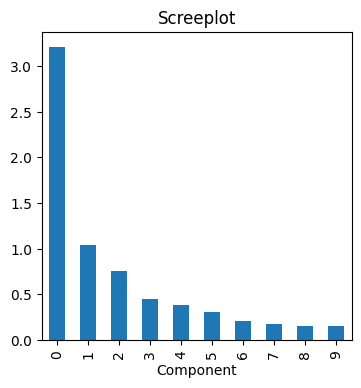

In [6]:
syms = sorted(['AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM', 'SLB', 'COP',
               'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST'])
top_sp = sp500_px.loc[sp500_px.index >= '2011-01-01', syms]

sp_pca = PCA()
sp_pca.fit(top_sp)

explained_variance = pd.DataFrame(sp_pca.explained_variance_)
ax = explained_variance.head(10).plot.bar(legend=False, figsize=(4, 4))
ax.set_xlabel('Component')
ax.set_title('Screeplot')
plt.show()

In [7]:
# Tambahan: persentase varians kumulatif untuk memilih jumlah komponen (ambang 80%)
cum = np.cumsum(sp_pca.explained_variance_ratio_)
summary = pd.DataFrame({'varians': sp_pca.explained_variance_,
                        'proporsi': sp_pca.explained_variance_ratio_,
                        'kumulatif': cum}, index=[f'PC{i+1}' for i in range(len(cum))])
print(summary.head(8).round(3))
print('\njumlah komponen untuk mencapai 80% varians:', int(np.argmax(cum >= 0.80)) + 1)

     varians  proporsi  kumulatif
PC1    3.215     0.445      0.445
PC2    1.037     0.143      0.588
PC3    0.759     0.105      0.693
PC4    0.449     0.062      0.755
PC5    0.384     0.053      0.809
PC6    0.301     0.042      0.850
PC7    0.205     0.028      0.879
PC8    0.175     0.024      0.903

jumlah komponen untuk mencapai 80% varians: 5


**Interpretasi hasil:**
- Varians komponen pertama sangat besar (±3,2), sedangkan komponen berikutnya jauh lebih kecil (1,04; 0,76; 0,45; ...). Ini sesuai dengan Figure 7-2 pada buku dan merupakan pola yang lazim: komponen pertama menangkap tren pasar secara keseluruhan.
- Komponen pertama menjelaskan 44,5% varians. Untuk mencapai ambang 80% diperlukan **5 komponen** (kumulatif 80,9%). Artinya 16 saham dapat diringkas menjadi 5 komponen dengan kehilangan sekitar 19% varians.
- Menurut buku, aturan seperti ini bersifat *ad hoc*. Pilihan akhir sebaiknya juga mempertimbangkan apakah komponennya dapat ditafsirkan.

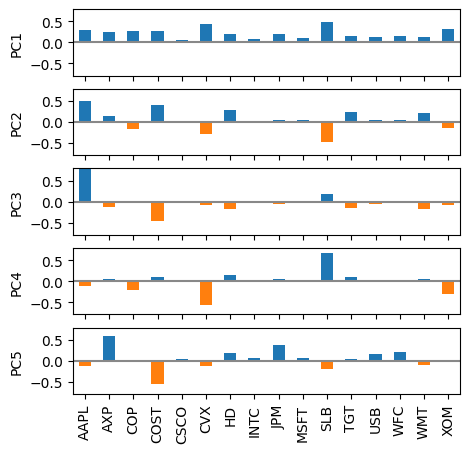

In [8]:
loadings = pd.DataFrame(sp_pca.components_[0:5, :], columns=top_sp.columns)
maxPC = 1.01 * np.max(np.max(np.abs(loadings.loc[0:5, :])))

f, axes = plt.subplots(5, 1, figsize=(5, 5), sharex=True)
for i, ax in enumerate(axes):
    pc_loadings = loadings.loc[i, :]
    colors = ['C0' if l > 0 else 'C1' for l in pc_loadings]
    ax.axhline(color='#888888')
    pc_loadings.plot.bar(ax=ax, color=colors)
    ax.set_ylabel(f'PC{i+1}')
    ax.set_ylim(-maxPC, maxPC)
plt.show()

**Interpretasi hasil:**
- **PC1:** semua bobot bertanda sama (positif). Ini lazim ketika semua kolom memiliki faktor bersama, yaitu **tren pasar saham secara keseluruhan**. Bobot terbesar ada pada saham energi (SLB, CVX, XOM).
- **PC2:** memisahkan saham energi (SLB, CVX, XOM, COP) dari saham lain (AAPL, COST, HD, TGT, WMT): mengukur perubahan harga **saham energi dibandingkan saham lainnya**.
- **PC3:** didominasi kontras antara **Apple (AAPL)** dan **Costco (COST)**.
- **PC4:** kontras **Schlumberger (SLB)** terhadap saham energi lain (CVX, XOM, COP).
- **PC5:** didominasi **perusahaan keuangan** (AXP, JPM, USB, WFC) yang berlawanan dengan COST.
- Tanda sebagian komponen (misalnya PC2, PC4, PC5) terbalik dibanding gambar di buku, tetapi tafsirannya tidak berubah karena tanda bobot dalam satu komponen bersifat sembarang.

---
## 2. Correspondence Analysis

### Teori

PCA tidak dapat dipakai untuk data kategorikal. Teknik yang agak berkaitan untuk data kategorikal adalah ***correspondence analysis***. Tujuannya mengenali **asosiasi antarkategori** atau antarfitur kategorikal. Kemiripannya dengan PCA terutama ada di "balik layar", yaitu aljabar matriks untuk penskalaan dimensi. Correspondence analysis dipakai terutama untuk **analisis grafis** data kategorikal berdimensi rendah, bukan sebagai langkah persiapan reduksi dimensi pada *big data* seperti PCA.

**Masukan** berupa tabel (tabel kontingensi): baris mewakili satu variabel, kolom mewakili variabel lain, dan sel berisi jumlah record. **Keluaran** (setelah operasi aljabar matriks) berupa ***biplot***, yaitu diagram pencar dengan sumbu yang diskalakan (disertai persentase varians yang dijelaskan tiap dimensi). Arti satuan pada sumbu tidak terhubung secara intuitif dengan data asli. Nilai utama biplot adalah memperlihatkan secara grafis variabel-variabel yang **berasosiasi** satu sama lain, yang ditandai oleh **kedekatannya** pada plot.

**Contoh.** Pada data `housetasks`, tugas-tugas rumah tangga disebar menurut apakah dikerjakan bersama atau sendiri (sumbu vertikal), dan apakah istri atau suami yang bertanggung jawab utama (sumbu horizontal).

### Kode

In [9]:
print(housetasks)

           Wife  Alternating  Husband  Jointly
Task                                          
Laundry     156           14        2        4
Main_meal   124           20        5        4
Dinner       77           11        7       13
Breakfast    82           36       15        7
Tidying      53           11        1       57
Dishes       32           24        4       53
Shopping     33           23        9       55
Official     12           46       23       15
Driving      10           51       75        3
Finances     13           13       21       66
Insurance     8            1       53       77
Repairs       0            3      160        2
Holidays      0            1        6      153


In [10]:
ca = prince.CA(n_components=2)
ca = ca.fit(housetasks)

print(ca.eigenvalues_summary)

          eigenvalue % of variance % of variance (cumulative)
component                                                    
0              0.543        48.69%                     48.69%
1              0.445        39.91%                     88.60%


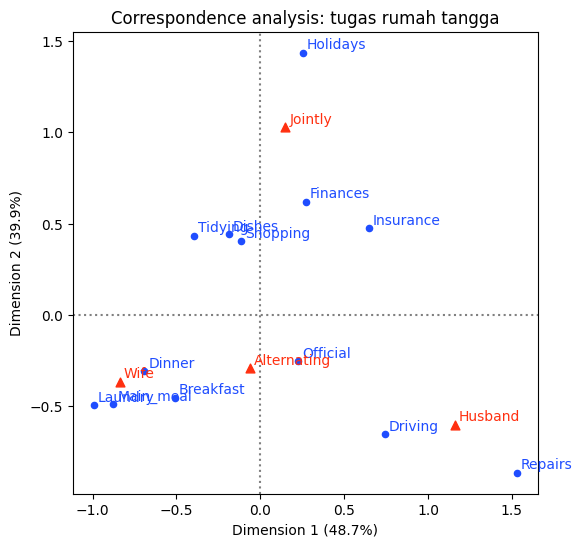

In [11]:
# Biplot (Figure 7-4): baris (tugas) berwarna biru, kolom (pelaku) berwarna merah
row_coords = ca.row_coordinates(housetasks)
col_coords = ca.column_coordinates(housetasks)
pct = ca.percentage_of_variance_

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(row_coords[0], row_coords[1], color='#1f4dff', s=20)
for name, (x, y) in row_coords.iterrows():
    ax.annotate(name, (x, y), color='#1f4dff', xytext=(3, 3), textcoords='offset points')
ax.scatter(col_coords[0], col_coords[1], color='#ff3010', marker='^', s=40)
for name, (x, y) in col_coords.iterrows():
    ax.annotate(name, (x, y), color='#ff3010', xytext=(3, 3), textcoords='offset points')
ax.axhline(0, color='gray', ls=':'); ax.axvline(0, color='gray', ls=':')
ax.set_xlabel(f'Dimension 1 ({pct[0]:.1f}%)')
ax.set_ylabel(f'Dimension 2 ({pct[1]:.1f}%)')
ax.set_title('Correspondence analysis: tugas rumah tangga')
plt.show()

**Interpretasi hasil:**
- Dimensi pertama menjelaskan **48,7%** dan dimensi kedua **39,9%** dari variasi (total 88,6%), persis seperti Figure 7-4 pada buku. Posisi relatif titiknya juga sama, hanya skala sumbu yang berbeda karena `prince` versi baru menormalkan koordinat dengan cara berbeda.
- **Sumbu horizontal** memisahkan tugas yang dikerjakan **istri** (kiri: *Laundry*, *Main_meal*, *Dinner*, *Breakfast*) dari tugas yang dikerjakan **suami** (kanan: *Repairs*, *Driving*).
- **Sumbu vertikal** memisahkan tugas yang dikerjakan **bersama** (atas: *Holidays*, *Finances*, *Insurance*, *Tidying*, *Dishes*, *Shopping*) dari tugas yang dikerjakan sendiri (bawah).
- Artinya, tugas yang letaknya **berdekatan dengan kategori pelaku** berasosiasi kuat dengan kategori tersebut. Contoh: *Repairs* sangat dekat dengan *Husband*, sesuai tabel (160 dari 165 pasangan). Seperti disebutkan buku, nilai pada sumbu tidak punya arti langsung; manfaat utamanya adalah melihat asosiasi lewat kedekatan titik.

---
## 3. K-Means Clustering

### Teori

*Clustering* adalah teknik membagi data menjadi kelompok-kelompok yang anggotanya saling mirip. Tujuannya mengidentifikasi kelompok data yang bermakna. Hasilnya dapat dipakai langsung, dianalisis lebih dalam, atau diteruskan sebagai fitur atau hasil ke model regresi atau klasifikasi. **K-means** adalah metode *clustering* pertama yang dikembangkan dan masih banyak dipakai, berkat kesederhanaan algoritmanya dan kemampuannya menangani data besar.

**Istilah kunci**
- **Cluster:** kelompok record yang mirip.
- **Cluster mean:** vektor rata-rata variabel untuk record-record dalam satu *cluster*.
- **K:** jumlah *cluster*.

K-means membagi data menjadi $K$ *cluster* dengan **meminimalkan jumlah kuadrat jarak** tiap record ke **rata-rata** *cluster*-nya. Ukuran ini disebut ***within-cluster sum of squares*** (*within-cluster SS*). K-means tidak menjamin ukuran semua *cluster* sama, tetapi menemukan *cluster* yang paling terpisah.

> **Normalisasi.** Variabel kontinu biasanya dinormalisasi (distandardisasi) dengan mengurangi rata-rata dan membagi simpangan baku. Jika tidak, variabel berskala besar akan mendominasi proses *clustering*.

**Contoh dua variabel dan $K = 4$.** Setiap record $(x_i, y_i)$ ditetapkan ke salah satu dari empat *cluster*. Jika *cluster* $k$ memiliki $n_k$ record, pusatnya adalah rata-rata titik-titik dalam *cluster* itu:

$$\bar{x}_k = \frac{1}{n_k}\sum_{i \in \text{Cluster } k} x_i \qquad\qquad \bar{y}_k = \frac{1}{n_k}\sum_{i \in \text{Cluster } k} y_i$$

Jumlah kuadrat dalam satu *cluster*:

$$SS_k = \sum_{i \in \text{Cluster } k} (x_i - \bar{x}_k)^2 + (y_i - \bar{y}_k)^2$$

K-means mencari penetapan record ke *cluster* yang meminimalkan $\sum_{k=1}^{4} SS_k$.

**Contoh penggunaan.** Selain mencari kelompok alami, K-means dipakai untuk **membagi data ke sejumlah kelompok yang ditentukan sebelumnya**. Misalnya, membagi return harian saham menjadi empat kelompok, seperti hari "turun tajam", "turun sedikit", "naik sedikit", dan "naik tajam". Return harian sudah dilaporkan dalam bentuk yang pada dasarnya terstandardisasi, sehingga tidak perlu dinormalisasi lagi.

### Kode: empat *cluster* dari return XOM dan CVX

In [12]:
df = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']]
kmeans = KMeans(n_clusters=4, random_state=0, n_init=10).fit(df)
df['cluster'] = kmeans.labels_
df.head()

,XOM,CVX,cluster
2011-01-03,0.736805,0.240681,1
2011-01-04,0.168668,-0.584516,3
2011-01-05,0.026631,0.446985,1
2011-01-06,0.248558,-0.919751,3
2011-01-07,0.337329,0.180511,1


In [13]:
centers = pd.DataFrame(kmeans.cluster_centers_, columns=['XOM', 'CVX'])
centers

,XOM,CVX
0,0.927032,1.346412
1,0.231540,0.316965
2,-1.144397,-1.757796
3,-0.330814,-0.574398


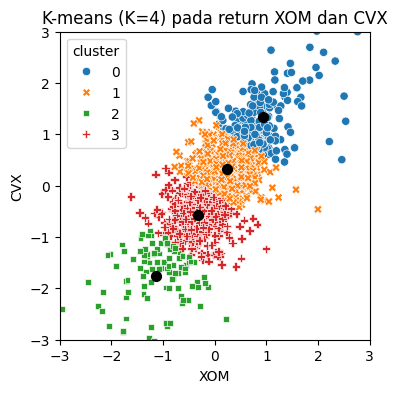

In [14]:
fig, ax = plt.subplots(figsize=(4, 4))
ax = sns.scatterplot(x='XOM', y='CVX', hue='cluster', style='cluster',
                     ax=ax, data=df, palette='tab10')
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
centers.plot.scatter(x='XOM', y='CVX', ax=ax, s=50, color='black')
ax.set_title('K-means (K=4) pada return XOM dan CVX')
plt.show()

**Interpretasi hasil:**
- K-means (K = 4) membagi return harian XOM dan CVX menjadi empat kelompok. Pusat *cluster* berada di sekitar (0,93; 1,35) dan (0,23; 0,32) untuk hari naik, serta (−1,14; −1,76) dan (−0,33; −0,57) untuk hari turun. Jadi dua *cluster* mewakili hari **"turun"** dan dua lagi hari **"naik"**, seperti pada buku.
- Perhatikan bahwa K-means **tetap membagi data menjadi empat bagian meskipun tidak ada pemisahan alami**: awan titiknya satu gumpalan memanjang, lalu "dipotong" menjadi empat wilayah. Ini berguna jika tujuan kita memang membagi data secara optimal menjadi kelompok.

### Teori: Algoritma K-means

K-means dapat diterapkan pada data dengan $p$ variabel $X_1, \dots, X_p$. Solusi *eksak* K-means sangat sulit dihitung, sehingga dipakai **algoritma heuristik** yang efisien untuk mendapatkan solusi **optimum lokal**.

Algoritma dimulai dengan $K$ yang ditentukan pengguna dan himpunan awal rata-rata *cluster*, lalu mengulang dua langkah:
1. **Penetapan:** tetapkan tiap record ke rata-rata *cluster* terdekat (diukur dengan jarak kuadrat).
2. **Pembaruan:** hitung rata-rata *cluster* yang baru berdasarkan penetapan tadi.

Algoritma **konvergen** ketika penetapan record ke *cluster* tidak lagi berubah. Pada iterasi pertama, rata-rata awal biasanya dibuat dengan menetapkan tiap record secara acak ke salah satu dari $K$ *cluster*, lalu menghitung rata-ratanya.

Karena tidak dijamin menemukan solusi terbaik, algoritma sebaiknya **dijalankan beberapa kali dengan inisialisasi acak yang berbeda**. Hasil akhirnya adalah iterasi dengan *within-cluster sum of squares* terendah. Pada `scikit-learn`, ini dikendalikan argumen `n_init` (jumlah pengulangan, bawaan 10 pada versi buku) dan `max_iter` (jumlah iterasi maksimum, bawaan 300).

### Tambahan: implementasi manual dua langkah K-means
Bagian ini **tidak ada di buku**. Dengan menulis algoritmanya sendiri, kita bisa melihat bahwa hasilnya bergantung pada titik awal acak (optimum lokal), dan bahwa menjalankannya beberapa kali lalu memilih yang terbaik memperbaiki hasil.

In [15]:
def kmeans_manual(X, k, seed, max_iter=300):
    rng = np.random.default_rng(seed)
    # inisialisasi: tetapkan tiap record secara acak ke salah satu cluster, lalu hitung rata-ratanya
    labels = rng.integers(0, k, size=len(X))
    for _ in range(max_iter):
        centers = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else X[rng.integers(len(X))]
                            for j in range(k)])
        # langkah 1: tetapkan tiap record ke rata-rata terdekat (jarak kuadrat)
        dist = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        new_labels = dist.argmin(axis=1)
        if np.array_equal(new_labels, labels):   # konvergen
            break
        labels = new_labels
    ss = sum(((X[labels == j] - centers[j]) ** 2).sum() for j in range(k))
    return labels, centers, ss

X_xy = df[['XOM', 'CVX']].values
ss_list = [kmeans_manual(X_xy, 4, seed)[2] for seed in range(10)]
print('within-cluster SS dari 10 inisialisasi acak:')
print(np.round(ss_list, 2))
print('\nterbaik (terkecil)      :', round(min(ss_list), 2))
print('terburuk (terbesar)     :', round(max(ss_list), 2))
print('inertia KMeans sklearn  :', round(kmeans.inertia_, 2))

within-cluster SS dari 10 inisialisasi acak:
[410.5  408.82 408.82 408.89 408.81 408.89 410.5  408.82 408.82 408.82]

terbaik (terkecil)      : 408.81
terburuk (terbesar)     : 410.5
inertia KMeans sklearn  : 408.89


**Interpretasi hasil (bagian tambahan):**
- Dari 10 inisialisasi acak, *within-cluster SS* berada di antara **408,81 dan 410,50**. Sebagian besar menemukan solusi mendekati 408,8, tetapi beberapa terjebak pada **optimum lokal** yang lebih buruk (410,50).
- Ini menjelaskan mengapa K-means perlu dijalankan beberapa kali dengan inisialisasi berbeda dan memilih hasil dengan SS terkecil, seperti yang dilakukan `n_init` pada `scikit-learn`. Hasil `KMeans` (408,89) berada dalam rentang yang sama.
- Pada data ini selisihnya kecil, tetapi pada data lain yang lebih rumit, inisialisasi yang buruk bisa menghasilkan solusi yang jauh lebih buruk.

### Kode: K-means pada banyak variabel (lima *cluster*)

In [16]:
syms = sorted(['AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM', 'SLB', 'COP',
               'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST'])
top_sp = sp500_px.loc[sp500_px.index >= '2011-01-01', syms]
kmeans = KMeans(n_clusters=5, random_state=0, n_init=10).fit(top_sp)

### Teori: Menafsirkan *cluster*

Bagian penting analisis *cluster* adalah menafsirkan *cluster* yang terbentuk. Dua keluaran terpenting K-means adalah **ukuran *cluster*** dan **rata-rata *cluster***. *Cluster* yang ukurannya sangat tidak seimbang dapat disebabkan oleh pencilan yang jauh, atau kelompok record yang sangat berbeda dari data lainnya. Keduanya layak diperiksa lebih lanjut.

In [17]:
print(Counter(kmeans.labels_))

Counter({np.int32(2): 299, np.int32(4): 291, np.int32(3): 255, np.int32(0): 180, np.int32(1): 106})


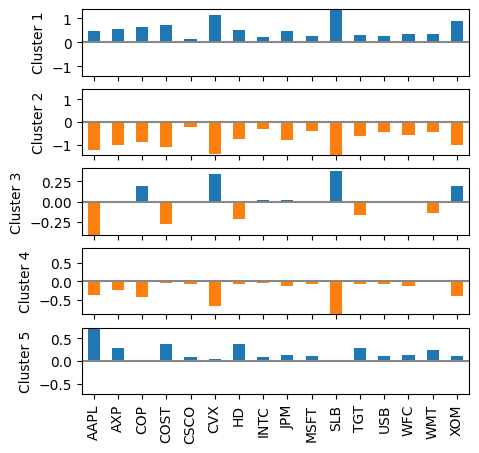

In [18]:
centers = pd.DataFrame(kmeans.cluster_centers_, columns=syms)

f, axes = plt.subplots(5, 1, figsize=(5, 5), sharex=True)
for i, ax in enumerate(axes):
    center = centers.loc[i, :]
    maxPC = 1.01 * np.max(np.max(np.abs(center)))
    colors = ['C0' if l > 0 else 'C1' for l in center]
    ax.axhline(color='#888888')
    center.plot.bar(ax=ax, color=colors)
    ax.set_ylabel(f'Cluster {i + 1}')
    ax.set_ylim(-maxPC, maxPC)
plt.show()

**Interpretasi hasil:**
- Ukuran kelima *cluster* relatif seimbang: 299, 291, 255, 180, dan 106 (buku: 106 sampai 288). *Cluster* yang sangat tidak seimbang akan menandakan pencilan atau kelompok yang sangat berbeda.
- Cara membaca (nomor *cluster* pada Python bisa berbeda dari buku karena inisialisasi acak):
  - **Cluster 1:** hampir semua saham naik, terutama saham energi (hari pasar naik).
  - **Cluster 2:** hampir semua saham turun tajam, terutama saham energi (hari pasar turun). Ini *cluster* terkecil (106 hari).
  - **Cluster 3:** saham energi (CVX, SLB, COP, XOM) naik sementara AAPL, COST, HD, WMT turun.
  - **Cluster 4:** saham energi turun, sedangkan saham lain hampir tidak bergerak.
  - **Cluster 5:** saham konsumen dan Apple (AAPL, COST, HD, TGT, WMT) naik, sedangkan saham energi hampir tidak bergerak.
- Berbeda dengan PCA, **tanda rata-rata *cluster* bermakna**: positif berarti hari naik, negatif berarti hari turun.

> **Analisis *cluster* versus PCA.** Plot rata-rata *cluster* mirip dengan melihat bobot (*loadings*) pada PCA. Perbedaan penting: pada analisis *cluster*, **tanda rata-rata *cluster* bermakna** (positif berarti saham naik, negatif berarti turun), sedangkan pada PCA tanda tidak bermakna. PCA mengidentifikasi **arah variasi utama**, sedangkan analisis *cluster* mencari **kelompok record yang letaknya saling berdekatan**.

### Teori: Memilih jumlah *cluster*

Algoritma K-means mengharuskan kita menentukan $K$. Kadang $K$ ditentukan oleh kebutuhan aplikasi. Contoh: perusahaan yang mengelola tenaga penjualan ingin mengelompokkan pelanggan menjadi beberapa "persona" untuk mengarahkan panggilan penjualan. Dua kelompok mungkin tidak cukup membedakan pelanggan, sedangkan delapan kelompok terlalu banyak untuk dikelola.

Jika tidak ada $K$ yang ditentukan oleh pertimbangan praktis, dapat dipakai pendekatan statistik. **Tidak ada satu metode standar** untuk menemukan jumlah *cluster* "terbaik". Pendekatan umum adalah **metode siku (*elbow method*)**: mencari titik ketika himpunan *cluster* menjelaskan "sebagian besar" varians data. Menambah *cluster* di luar titik itu hanya menambah sedikit varians yang dijelaskan. "Siku" adalah titik tempat varians kumulatif yang dijelaskan mulai mendatar setelah naik tajam.

Pada data yang tidak memiliki *cluster* yang jelas, tidak ada siku yang tegas karena kenaikan varians yang dijelaskan menurun perlahan. Ini wajar dan justru mencerminkan sifat data. Ujian terpenting dalam menentukan jumlah *cluster* adalah: **seberapa besar kemungkinan *cluster* itu terulang pada data baru?** Apakah *cluster* dapat ditafsirkan, dan apakah berkaitan dengan karakteristik umum data atau hanya mencerminkan satu contoh tertentu? Hal ini dapat dinilai sebagian dengan *cross-validation*.

> Ada cara-cara yang lebih formal, misalnya statistik *gap* yang diusulkan Tibshirani, Walther, dan Hastie. Untuk sebagian besar aplikasi, pendekatan teoretis seperti itu mungkin tidak diperlukan.

### Kode: metode siku

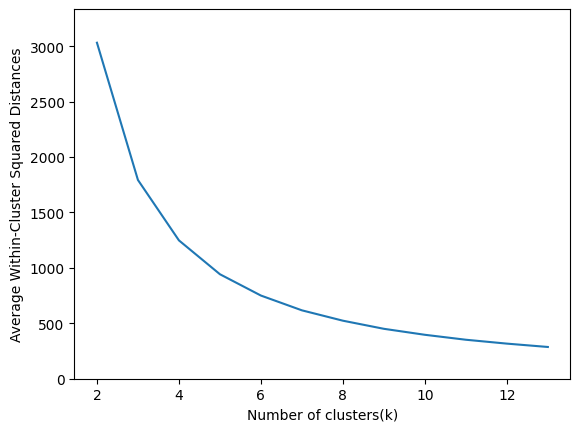

In [19]:
inertia = []
for n_clusters in range(2, 14):
    kmeans = KMeans(n_clusters=n_clusters, random_state=0, n_init=10).fit(top_sp)
    inertia.append(kmeans.inertia_ / n_clusters)

inertias = pd.DataFrame({'n_clusters': range(2, 14), 'inertia': inertia})
ax = inertias.plot(x='n_clusters', y='inertia')
plt.xlabel('Number of clusters(k)')
plt.ylabel('Average Within-Cluster Squared Distances')
plt.ylim((0, 1.1 * inertias.inertia.max()))
ax.legend().set_visible(False)
plt.show()

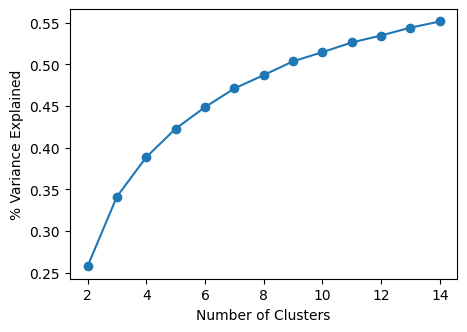

,0,1,2,3,4,5,6,7,8,9,10,11,12
n_clusters,2.000,3.000,4.000,5.000,6.000,7.000,8.000,9.000,10.000,11.000,12.000,13.000,14.000
pct_var,0.258,0.341,0.389,0.423,0.449,0.471,0.487,0.504,0.515,0.526,0.535,0.544,0.551


In [20]:
# Tambahan: versi "persentase varians yang dijelaskan" seperti pada Figure 7-7 (versi R di buku)
total_ss = ((top_sp - top_sp.mean()) ** 2).sum().sum()
pct_var = []
for n_clusters in range(2, 15):
    km = KMeans(n_clusters=n_clusters, random_state=0, n_init=10).fit(top_sp)
    pct_var.append(1 - km.inertia_ / total_ss)    # between-SS / total-SS

pv = pd.DataFrame({'n_clusters': range(2, 15), 'pct_var': pct_var})
ax = pv.plot(x='n_clusters', y='pct_var', marker='o', legend=False, figsize=(5, 3.5))
ax.set_xlabel('Number of Clusters'); ax.set_ylabel('% Variance Explained')
plt.show()
pv.round(3).T

**Interpretasi hasil:**
- Kurva rata-rata jarak kuadrat dalam *cluster* menurun terus tanpa ada patahan yang tegas. Versi persentase varians yang dijelaskan naik dari 25,8% (K = 2) menjadi 55,1% (K = 14), dengan kenaikan yang makin kecil secara bertahap (misalnya +8,3 poin dari K = 2 ke 3, tetapi hanya sekitar +0,7 sampai +0,9 poin per tambahan *cluster* di atas K = 11).
- **Tidak ada "siku" yang jelas.** Menurut buku, ini lazim pada data yang tidak memiliki *cluster* yang terdefinisi dengan baik, dan justru memperlihatkan sifat data. Karena itu pemilihan K sebaiknya mempertimbangkan kegunaan praktis dan apakah *cluster* dapat ditafsirkan.

---
## 4. Hierarchical Clustering

### Teori

***Hierarchical clustering*** (pengelompokan hierarkis) adalah alternatif K-means yang dapat menghasilkan *cluster* yang sangat berbeda. Keunggulannya:
- Pengguna dapat **memvisualisasikan pengaruh penentuan jumlah *cluster* yang berbeda**.
- Lebih peka dalam menemukan **kelompok atau record pencilan**.
- Mudah ditafsirkan karena ditampilkan dalam grafik yang intuitif.

Kelemahannya: tidak *scalable* untuk data dengan jutaan record. Bahkan untuk data berukuran sedang (puluhan ribu record), kebutuhan komputasinya bisa besar. Karena itu penerapannya umumnya pada data yang relatif kecil.

**Istilah kunci**
- **Dendrogram:** representasi visual record dan hierarki *cluster* tempat record itu berada.
- **Distance (jarak):** ukuran kedekatan satu record dengan record lain.
- **Dissimilarity (ketidakmiripan):** ukuran kedekatan satu *cluster* dengan *cluster* lain.

Pengelompokan hierarkis dibangun dari dua komponen dasar:
- **Metrik jarak** $d_{i,j}$ untuk mengukur jarak antara dua record $i$ dan $j$.
- **Metrik ketidakmiripan** $D_{A,B}$ untuk mengukur perbedaan antara dua *cluster* $A$ dan $B$, berdasarkan jarak $d_{i,j}$ antaranggota keduanya.

Untuk data numerik, pilihan yang paling penting adalah metrik ketidakmiripan. Pengelompokan hierarkis dimulai dengan **menjadikan tiap record sebagai *cluster* sendiri**, lalu mengulang penggabungan *cluster* yang paling tidak berbeda.

**Perbedaan dengan K-means.** Fungsi pengelompokan hierarkis bekerja pada **jarak berpasangan** antarrecord, bukan pada data langsung. Selain itu, algoritma ini mengelompokkan **baris** tabel. Jika kita ingin mengelompokkan *perusahaan* (bukan hari), tabel harus di-**transpose** sehingga saham berada di baris dan tanggal di kolom.

### Kode: mengelompokkan saham
`linkage` dengan metode `complete` dipakai untuk membentuk hierarki.

In [21]:
syms1 = ['AAPL', 'AMZN', 'AXP', 'COP', 'COST', 'CSCO', 'CVX', 'GOOGL', 'HD',
         'INTC', 'JPM', 'MSFT', 'SLB', 'TGT', 'USB', 'WFC', 'WMT', 'XOM']
df = sp500_px.loc[sp500_px.index >= '2011-01-01', syms1].transpose()

Z = linkage(df, method='complete')
print('bentuk df (saham x hari):', df.shape)
print('bentuk matriks linkage  :', Z.shape, '(tiap baris = satu penggabungan dua cluster)')

bentuk df (saham x hari): (18, 1131)
bentuk matriks linkage  : (17, 4) (tiap baris = satu penggabungan dua cluster)


### Teori: Dendrogram

Pengelompokan hierarkis dapat ditampilkan sebagai pohon yang disebut **dendrogram** (dari kata Yunani *dendro* = pohon dan *gramma* = gambar). **Daun** pohon adalah record. **Panjang cabang** menunjukkan tingkat ketidakmiripan antara *cluster* yang bersangkutan.

Berbeda dengan K-means, **jumlah *cluster* tidak perlu ditentukan sebelumnya**. Secara grafis, kita dapat memotong dendrogram dengan **garis horizontal yang digeser naik atau turun**: sebuah *cluster* ditentukan di setiap titik garis itu memotong garis vertikal. Untuk mengambil jumlah *cluster* tertentu, dipakai `fcluster`.

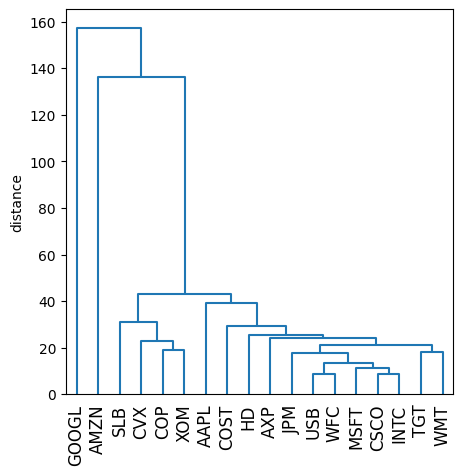

In [22]:
fig, ax = plt.subplots(figsize=(5, 5))
dendrogram(Z, labels=df.index, ax=ax, color_threshold=0)
plt.xticks(rotation=90)
ax.set_ylabel('distance')
plt.show()

In [23]:
memb = fcluster(Z, 4, criterion='maxclust')
memb = pd.Series(memb, index=df.index)
for key, item in memb.groupby(memb):
    print(f"{key} : {', '.join(item.index)}")

1 : COP, CVX, SLB, XOM
2 : AAPL, AXP, COST, CSCO, HD, INTC, JPM, MSFT, TGT, USB, WFC, WMT
3 : AMZN
4 : GOOGL


**Interpretasi hasil:**
- Dengan empat *cluster*: (1) **saham minyak** (COP, CVX, SLB, XOM) berada dalam satu kelompok, (2) **Google (GOOGL)** sendirian, (3) **Amazon (AMZN)** sendirian, dan (4) 12 saham lainnya.
- Ini sama dengan temuan buku: return GOOGL dan AMZN sangat berbeda satu sama lain dan dari saham lain, saham minyak membentuk kelompok tersendiri, dan sisanya relatif mirip.
- Pada dendrogram, GOOGL (jarak ±157) dan AMZN (±136) baru bergabung dengan kelompok lain pada ketinggian yang sangat besar, sedangkan saham minyak sudah bergabung satu sama lain pada jarak rendah (di bawah ±31). Apple (AAPL) bergabung dengan kelompok besar pada jarak ±39, lebih tinggi daripada kebanyakan saham lain, sehingga relatif berbeda. Namun pada potongan empat *cluster* AAPL masih termasuk kelompok besar.

### Teori: Algoritma aglomeratif

Algoritma utama pengelompokan hierarkis adalah **algoritma aglomeratif**, yang menggabungkan *cluster* yang mirip secara berulang. Algoritma dimulai dari tiap record sebagai *cluster* beranggota tunggal, lalu membangun *cluster* yang makin besar. Langkah pertama adalah menghitung jarak antara semua pasangan record. Untuk dua record $x$ dan $y$, jarak Euclidean:

$$d(x,y)=\sqrt{(x_1-y_1)^2+(x_2-y_2)^2+\cdots+(x_p-y_p)^2}$$

Untuk jarak antar-*cluster* $A = \{a_1, \dots, a_m\}$ dan $B = \{b_1, \dots, b_q\}$, ketidakmiripan $D(A, B)$ dihitung dari jarak antara anggota $A$ dan anggota $B$. Salah satu ukurannya adalah ***complete linkage***, yaitu **jarak maksimum** di antara semua pasangan record dari $A$ dan $B$:

$$D(A,B)=\max d(a_i,b_j)\quad\text{untuk semua pasangan } i,j$$

Langkah-langkah algoritma aglomeratif:
1. Buat himpunan awal *cluster*, setiap *cluster* berisi satu record.
2. Hitung ketidakmiripan $D(C_k, C_\ell)$ antara semua pasangan *cluster*.
3. Gabungkan dua *cluster* $C_k$ dan $C_\ell$ yang **paling tidak berbeda**.
4. Jika masih ada lebih dari satu *cluster*, kembali ke langkah 2. Jika tidak, selesai.

### Teori: Ukuran ketidakmiripan

Ada empat ukuran yang umum:

| Ukuran | Definisi | Karakter |
|---|---|---|
| ***Complete linkage*** | Jarak **maksimum** antarpasangan record | Menghasilkan *cluster* yang anggotanya mirip |
| ***Single linkage*** | Jarak **minimum** antarpasangan record | Metode "rakus" (*greedy*): *cluster* dapat berisi anggota yang sangat berbeda |
| ***Average linkage*** | **Rata-rata** semua pasangan jarak | Kompromi antara *single* dan *complete* |
| ***Minimum variance* (Ward)** | Meminimalkan *within-cluster SS* | Mirip dengan K-means |

### Kode: membandingkan keempat ukuran pada return XOM dan CVX
Buku menampilkan perbandingan ini pada Figure 7-9 tanpa kode Python, sehingga kodenya ditulis sendiri. Keempat ukuran masing-masing menyisakan empat *cluster*.

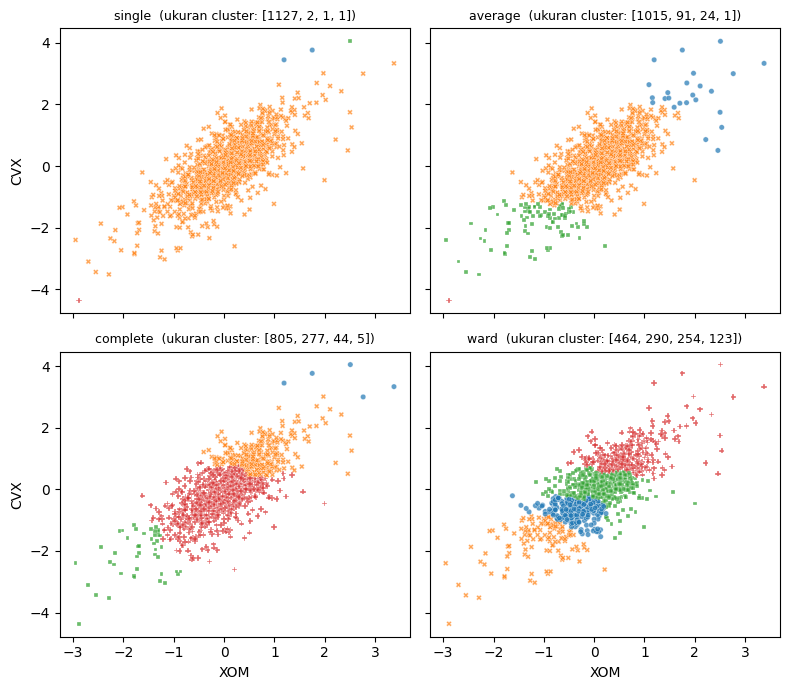

In [24]:
xy = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']]

fig, axes = plt.subplots(2, 2, figsize=(8, 7), sharex=True, sharey=True)
for ax, method in zip(axes.ravel(), ['single', 'average', 'complete', 'ward']):
    Zm = linkage(xy, method=method)
    labels = fcluster(Zm, 4, criterion='maxclust')
    sizes = sorted(Counter(labels).values(), reverse=True)
    sns.scatterplot(x=xy['XOM'], y=xy['CVX'], hue=labels, style=labels,
                    palette='tab10', ax=ax, legend=False, s=15, alpha=0.7)
    ax.set_title(f'{method}  (ukuran cluster: {sizes})', fontsize=9)
plt.tight_layout()
plt.show()

**Interpretasi hasil:**
- Hasil keempat ukuran ketidakmiripan **sangat berbeda**, seperti pada Figure 7-9 buku. Ukuran *cluster* (dari terbesar ke terkecil):
  - ***single***: 1.127, 2, 1, 1. Hampir semua titik masuk satu *cluster*; tiga lainnya hanya pencilan.
  - ***average***: 1.015, 91, 24, 1.
  - ***complete***: 805, 277, 44, 5.
  - ***ward***: 464, 290, 254, 123. Ukuran paling seimbang.
- Kecuali *ward*, semua ukuran menghasilkan setidaknya satu *cluster* yang hanya berisi sedikit titik pencilan. Metode *minimum variance* (*ward*) menghasilkan pembagian paling mirip dengan K-means (bandingkan dengan hasil K-means sebelumnya), karena sama-sama meminimalkan *within-cluster SS*.

---
## 5. Model-Based Clustering

### Teori

K-means dan pengelompokan hierarkis berbasis **heuristik**: keduanya mencari *cluster* yang anggotanya saling dekat berdasarkan data secara langsung, tanpa model probabilitas. Dalam 20 tahun terakhir dikembangkan **metode *clustering* berbasis model** (*model-based clustering*), dengan kontribusi penting dari Adrian Raftery dan peneliti lain di University of Washington. Metode ini berlandaskan teori statistik dan memberi cara yang lebih ketat untuk menentukan sifat dan jumlah *cluster*.

Metode ini berguna misalnya ketika ada satu kelompok record yang **mirip satu sama lain tetapi tidak harus berdekatan** (misalnya saham teknologi dengan varians return tinggi), dan kelompok lain yang mirip **sekaligus berdekatan** (misalnya saham utilitas dengan varians rendah). K-means tidak dapat membedakan keduanya dengan baik.

### Teori: Distribusi normal multivariat

Metode paling umum bertumpu pada **distribusi normal multivariat**, yaitu perluasan distribusi normal ke sekumpulan $p$ variabel $X_1, \dots, X_p$. Distribusi ini ditentukan oleh vektor rata-rata $\mu = (\mu_1, \dots, \mu_p)$ dan **matriks kovarians** $\Sigma$:

$$\Sigma=\begin{bmatrix}\sigma_1^2 & \sigma_{1,2} & \cdots & \sigma_{1,p}\\ \sigma_{2,1} & \sigma_2^2 & \cdots & \sigma_{2,p}\\ \vdots & \vdots & \ddots & \vdots\\ \sigma_{p,1} & \sigma_{p,2} & \cdots & \sigma_p^2\end{bmatrix}$$

Matriks kovarians simetris ($\sigma_{i,j}=\sigma_{j,i}$), sehingga hanya ada $p(p-1)/2$ suku kovarians. Totalnya terdapat $p(p-1)/2 + p$ parameter. Distribusi ditulis $X_1,\dots,X_p \sim N_p(\mu, \Sigma)$, yaitu cara simbolis untuk mengatakan bahwa semua variabel berdistribusi normal dan seluruh distribusi dijelaskan sepenuhnya oleh vektor rata-rata dan matriks kovarians.

**Contoh (Figure 7-10).** Rata-rata $\mu_x = 0{,}5$ dan $\mu_y = -0{,}5$, dengan matriks kovarians $\Sigma = \begin{bmatrix}1 & 1\\ 1 & 2\end{bmatrix}$. Karena kovarians $\sigma_{xy}$ positif, $X$ dan $Y$ berkorelasi positif. Kontur probabilitas 0,5 mencakup 50% distribusi, kontur 0,95 mencakup 95%, dan seterusnya.

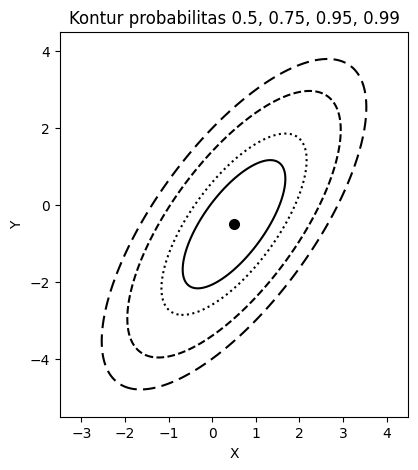

In [25]:
# Figure 7-10: kontur probabilitas distribusi normal dua dimensi
mu = np.array([0.5, -0.5])
Sigma = np.array([[1, 1], [1, 2]])

xx, yy = np.meshgrid(np.linspace(-3.5, 4.5, 400), np.linspace(-5.5, 4.5, 400))
pts = np.stack([xx.ravel(), yy.ravel()], axis=1) - mu
# jarak Mahalanobis kuadrat dari pusat
m2 = np.einsum('ij,jk,ik->i', pts, np.linalg.inv(Sigma), pts).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(4.5, 5))
levels = [0.5, 0.75, 0.95, 0.99]
styles = ['-', ':', '--', (0, (6, 3))]
for p, ls in zip(levels, styles):
    # untuk normal 2D, jarak Mahalanobis kuadrat berdistribusi chi-kuadrat dengan 2 derajat bebas
    ax.contour(xx, yy, m2, levels=[stats.chi2.ppf(p, df=2)], colors='k', linestyles=[ls])
ax.plot(*mu, 'ko', ms=7)
ax.set_xlabel('X'); ax.set_ylabel('Y')
ax.set_title('Kontur probabilitas 0.5, 0.75, 0.95, 0.99')
plt.show()

### Teori: Campuran distribusi normal (*mixtures of normals*)

Gagasan utama *model-based clustering*: **setiap record diasumsikan berasal dari salah satu dari $K$ distribusi normal multivariat**, dengan $K$ adalah jumlah *cluster*. Tiap distribusi memiliki rata-rata $\mu$ dan matriks kovarians $\Sigma$ sendiri. Jika ada dua variabel $X$ dan $Y$, setiap baris $(X_i, Y_i)$ dimodelkan sebagai sampel dari salah satu dari $N(\mu_1,\Sigma_1), N(\mu_2,\Sigma_2), \dots, N(\mu_K,\Sigma_K)$.

**Contoh intuitif.** Misalkan kita mengukur tinggi badan sekelompok orang tanpa mengetahui jenis kelaminnya. Tinggi badan keseluruhan tampak seperti satu distribusi yang agak lebar, tetapi sebenarnya merupakan campuran dua distribusi normal: satu untuk pria (rata-rata lebih tinggi) dan satu untuk wanita (rata-rata lebih rendah). Model campuran berusaha menemukan kedua distribusi itu sekaligus menentukan untuk tiap orang, distribusi mana yang paling mungkin menghasilkannya.

Di R tersedia paket `mclust`; di Python dipakai `sklearn.mixture.GaussianMixture`.

### Kode: dua komponen pada return XOM dan CVX
`random_state` diatur agar hasil dapat diulang. Buku mencatat bahwa hasil dapat sedikit berbeda antarproses karena algoritma ini memakai angka acak.

In [26]:
df = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']]
mclust = GaussianMixture(n_components=2, random_state=0).fit(df)
print('BIC:', round(mclust.bic(df), 2))
print('ukuran cluster:', Counter(mclust.predict(df)))

BIC: 4589.82
ukuran cluster: Counter({np.int64(1): 918, np.int64(0): 213})


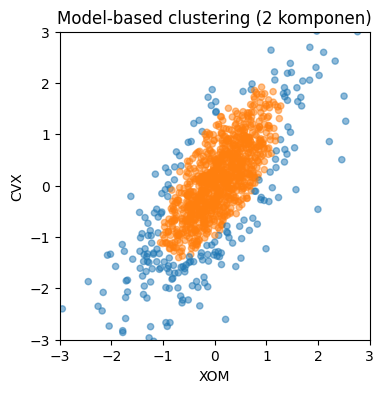

In [27]:
fig, ax = plt.subplots(figsize=(4, 4))
colors = [f'C{c}' for c in mclust.predict(df)]
df.plot.scatter(x='XOM', y='CVX', c=colors, alpha=0.5, ax=ax)
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_title('Model-based clustering (2 komponen)')
plt.show()

In [28]:
print('Mean')
print(mclust.means_)
print('Covariances')
print(mclust.covariances_)

Mean
[[-0.05050178 -0.21237957]
 [ 0.07225117  0.10452744]]
Covariances
[[[0.97385279 0.98028909]
  [0.98028909 1.67646834]]

 [[0.26868436 0.27606914]
  [0.27606914 0.51762673]]]


**Interpretasi hasil:**
- Model menemukan **dua *cluster***: satu berisi 918 hari di bagian tengah data (varians kecil) dan satu berisi 213 hari di tepi luar data (varians besar). Pada buku, `mclust` menemukan 963 dan 168 hari, perbedaan wajar karena implementasi dan angka acak berbeda.
- Rata-rata kedua distribusi mirip, tetapi **matriks kovarians distribusi kedua jauh lebih besar** (varians XOM ±0,97 dan CVX ±1,68, dibanding ±0,27 dan ±0,52). Persis seperti penjelasan buku.
- Hasil ini sangat berbeda dengan K-means dan pengelompokan hierarkis yang menghasilkan *cluster* yang padat. Return saham sebenarnya berdistribusi dengan **ekor lebih panjang** daripada distribusi normal. Untuk menanganinya, model memadankan satu distribusi pada sebagian besar data, lalu distribusi kedua dengan varians lebih besar untuk menampung pencilan.

### Teori: Memilih jumlah *cluster* dengan BIC

Berbeda dengan K-means dan pengelompokan hierarkis, `mclust` (di R) **memilih jumlah *cluster* secara otomatis**. Caranya: memilih jumlah *cluster* yang memberikan nilai ***Bayesian Information Criterion* (BIC)** terbaik. BIC mirip dengan AIC. BIC bekerja dengan memilih model yang paling cocok dengan data **disertai penalti atas jumlah parameter** model. Pada *clustering* berbasis model, menambah *cluster* selalu memperbaiki kecocokan, tetapi dengan biaya tambahan parameter. BIC menyeimbangkan keduanya sehingga mencegah *overfitting*.

> **Perhatian tanda.** Pada umumnya BIC **diminimalkan**. Penulis paket `mclust` mendefinisikan BIC dengan tanda terbalik agar plotnya lebih mudah ditafsirkan (nilai terbesar terbaik). Implementasi `GaussianMixture` memakai definisi biasa: nilai BIC positif dan harus **diminimalkan**.

`mclust` mencoba 14 model yang berbeda untuk tiap jumlah komponen karena ada banyak cara memparameterkan matriks kovarians $\Sigma$. `GaussianMixture` hanya menyediakan empat jenis kovarians (`full`, `tied`, `diag`, `spherical`), sehingga garis pada plotnya hanya empat.

### Kode

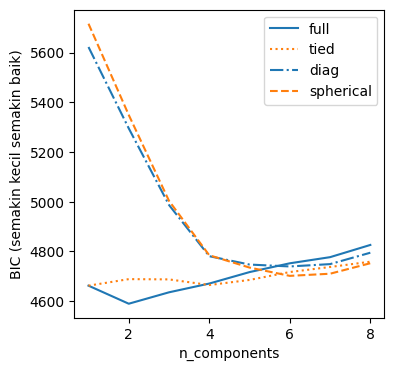

BIC terkecil: {'bic': 4589.820626249873, 'n_components': 2, 'covariance_type': 'full'}


In [29]:
results = []
covariance_types = ['full', 'tied', 'diag', 'spherical']
for n_components in range(1, 9):
    for covariance_type in covariance_types:
        mclust = GaussianMixture(n_components=n_components, warm_start=True,
                                 covariance_type=covariance_type, random_state=0)
        mclust.fit(df)
        results.append({
            'bic': mclust.bic(df),
            'n_components': n_components,
            'covariance_type': covariance_type,
        })

results = pd.DataFrame(results)

colors = ['C0', 'C1', 'C2', 'C3']
styles = ['C0-', 'C1:', 'C0-.', 'C1--']

fig, ax = plt.subplots(figsize=(4, 4))
for i, covariance_type in enumerate(covariance_types):
    subset = results.loc[results.covariance_type == covariance_type, :]
    subset.plot(x='n_components', y='bic', ax=ax, label=covariance_type,
                kind='line', style=styles[i])
ax.set_ylabel('BIC (semakin kecil semakin baik)')
plt.show()

best = results.loc[results.bic.idxmin()]
print('BIC terkecil:', best.to_dict())

**Interpretasi hasil:**
- Nilai BIC terkecil (terbaik) adalah **4.589,82** pada **2 komponen** dengan kovarians `full`. Jadi BIC memilih jumlah *cluster* yang sama dengan hasil `mclust` pada buku (dua komponen).
- Untuk kovarians `full`, BIC turun dari 1 ke 2 komponen, lalu **naik lagi** pada 3 komponen atau lebih. Kenaikan ini menunjukkan penalti atas bertambahnya parameter melebihi peningkatan kecocokan, sehingga komponen tambahan dianggap *overfitting*. Kovarians `tied` relatif datar di kisaran 4.660 sampai 4.750.
- Kovarians `diag` dan `spherical` memberi BIC yang jauh lebih tinggi pada 1 sampai 3 komponen, turun sampai sekitar 4 sampai 6 komponen, tetapi tidak pernah mencapai nilai terendah model `full` dengan 2 komponen.
- Berbeda dengan metode siku pada K-means yang tidak memiliki patahan jelas, kurva `full` memiliki titik terendah yang tegas sehingga pemilihan jumlah *cluster* lebih mudah.

### Teori: Keterbatasan *model-based clustering*

*Model-based clustering* adalah bidang yang kaya dan berkembang pesat, sedangkan cakupan di buku hanya sebagian kecil. Menurut buku, mendalami nuansanya mungkin lebih berat daripada yang dibutuhkan untuk sebagian besar masalah data scientist. Keterbatasannya:
- Metode ini **memerlukan asumsi model** untuk data, dan hasil *cluster* sangat bergantung pada asumsi itu.
- Kebutuhan komputasinya **lebih tinggi** daripada pengelompokan hierarkis, sehingga sulit diskalakan untuk data besar.
- Algoritmanya lebih rumit dan kurang mudah diakses dibanding metode lain.

---
## 6. Scaling and Categorical Variables

### Teori

Teknik *unsupervised learning* pada umumnya mengharuskan data **diskalakan dengan tepat**. Ini berbeda dengan banyak teknik regresi dan klasifikasi yang tidak peka terhadap skala (pengecualian: K-Nearest Neighbors).

**Istilah kunci**
- **Scaling (penskalaan):** memampatkan atau meregangkan data, biasanya agar beberapa variabel berada pada skala yang sama.
- **Normalization:** salah satu metode penskalaan, yaitu mengurangi rata-rata dan membagi simpangan baku (sinonim: *standardization*).
- **Gower's distance:** algoritma penskalaan untuk data campuran numerik dan kategorikal yang membawa semua variabel ke rentang 0 sampai 1.

**Contoh masalahnya.** Pada data pinjaman, satuan dan besaran variabel sangat berbeda: sebagian kecil (misalnya lama bekerja dalam tahun, puluhan), sebagian sangat besar (misalnya jumlah pinjaman dalam dolar, puluhan ribu). Jika tidak diskalakan, PCA, K-means, dan metode *clustering* lain akan **didominasi variabel bernilai besar** dan mengabaikan variabel bernilai kecil.

### Kode: K-means tanpa penskalaan
Kita terapkan K-means pada data pinjaman yang *default* tanpa normalisasi.

In [30]:
defaults = loan_data.loc[loan_data['outcome'] == 'default',]
columns = ['loan_amnt', 'annual_inc', 'revol_bal', 'open_acc',
           'dti', 'revol_util']

df = defaults[columns]
kmeans = KMeans(n_clusters=4, random_state=1, n_init=10).fit(df)
counts = Counter(kmeans.labels_)

centers = pd.DataFrame(kmeans.cluster_centers_, columns=columns)
centers['size'] = [counts[i] for i in range(4)]
centers

,loan_amnt,annual_inc,revol_bal,open_acc,dti,revol_util,size
0,10622.742745,42577.468936,10301.719025,9.594482,17.708084,58.125058,13949
1,18312.358465,83793.803650,19740.572666,11.677767,16.771941,62.307165,7509
2,21924.589455,166721.916162,39129.990493,12.566119,13.374546,63.505161,1161
3,22570.192308,489783.403846,85161.346154,13.326923,6.907500,59.651923,52


**Interpretasi hasil:**
- Tanpa penskalaan, *cluster* **didominasi `annual_inc` dan `revol_bal`**, yang bernilai puluhan hingga ratusan ribu. *Cluster* 3 hanya berisi **52 peminjam** dengan pendapatan rata-rata sangat tinggi (±490 ribu) dan saldo kredit ±85 ribu. *Cluster* lain terutama dibedakan oleh besar pendapatan dan saldo.
- Ukuran *cluster* sangat tidak seimbang (13.949, 7.509, 1.161, dan 52). Hasilnya cocok dengan tabel pada buku (13.902, 7.525, 1.192, dan 52).
- Variabel berskala kecil seperti `open_acc` dan `dti` nyaris tidak ikut menentukan pembentukan *cluster*.

### Teori dan kode: K-means dengan penskalaan (z-score)

Cara umum menskalakan variabel adalah mengubahnya menjadi *z-score*, yaitu mengurangi rata-rata lalu membaginya dengan simpangan baku. Ini disebut **standardisasi** atau **normalisasi**:

$$z=\frac{x-\bar{x}}{s}$$

Pusat *cluster* kemudian dikembalikan ke satuan asli dengan `inverse_transform` supaya mudah ditafsirkan. Jika dibiarkan dalam bentuk *z-score*, nilainya sulit dibaca.

In [31]:
scaler = preprocessing.StandardScaler()
df0 = scaler.fit_transform(df * 1.0)

kmeans = KMeans(n_clusters=4, random_state=1, n_init=10).fit(df0)
counts = Counter(kmeans.labels_)

centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_),
                       columns=columns)
centers['size'] = [counts[i] for i in range(4)]
centers

,loan_amnt,annual_inc,revol_bal,open_acc,dti,revol_util,size
0,25911.917975,116436.183541,32850.199242,12.417163,16.199721,66.075439,3704
1,10353.683267,53506.668364,6049.698547,8.699868,11.347761,30.578083,5306
2,13394.423718,55638.622956,16409.356247,14.235910,24.232926,59.758967,6292
3,10475.352447,51152.617595,11505.237088,7.473092,15.754014,77.654009,7369


**Interpretasi hasil:**
- Setelah distandardisasi, ukuran *cluster* jauh lebih seimbang (3.704; 5.306; 6.292; 7.369) dan tidak lagi didominasi `annual_inc` dan `revol_bal`. Hasil ini cocok dengan buku (3.713; 5.309; 6.294; 7.355).
- Struktur yang lebih menarik muncul: misalnya satu *cluster* berisi peminjam dengan **`revol_util` rendah (±31%)**, satu *cluster* dengan **`revol_util` tinggi (±78%)**, satu *cluster* berisi peminjam dengan **pinjaman dan pendapatan besar** (±25,9 ribu dan ±116 ribu), dan satu *cluster* dengan **`dti` tinggi (±24)** serta jumlah akun terbuka tertinggi.
- Pusat *cluster* dikembalikan ke satuan asli dengan `inverse_transform` sehingga mudah dibaca. Jika tidak, nilainya berupa *z-score* yang sulit ditafsirkan.

> **Penskalaan pada PCA.** Menggunakan *z-score* setara dengan memakai **matriks korelasi** (bukan matriks kovarians) untuk menghitung komponen utama. Perangkat lunak PCA biasanya menyediakan opsi memakai matriks korelasi (di R, argumen `cor` pada `princomp`). Pada `scikit-learn`, caranya adalah menstandardisasi data lebih dulu, misalnya dengan `StandardScaler`.

### Teori: Variabel dominan (*dominant variables*)

Bahkan ketika semua variabel diukur pada skala yang sama dan mencerminkan kepentingan relatif yang benar (misalnya pergerakan harga saham), kadang berguna untuk menskalakan ulang variabel. Contoh: tambahkan Google (GOOGL) dan Amazon (AMZN) ke analisis PCA sebelumnya. Harga kedua saham ini sangat tinggi dan bergerak jauh lebih besar, sehingga variabilitasnya mendominasi.

### Kode

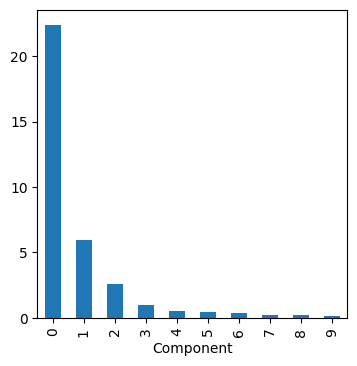

In [32]:
syms = ['GOOGL', 'AMZN', 'AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM',
        'SLB', 'COP', 'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST']
top_sp1 = sp500_px.loc[sp500_px.index >= '2005-01-01', syms]

sp_pca1 = PCA()
sp_pca1.fit(top_sp1)

explained_variance = pd.DataFrame(sp_pca1.explained_variance_)
ax = explained_variance.head(10).plot.bar(legend=False, figsize=(4, 4))
ax.set_xlabel('Component')
plt.show()

In [33]:
loadings = pd.DataFrame(sp_pca1.components_[0:2, :], columns=top_sp1.columns)
loadings.transpose().round(3)

,0,1
GOOGL,0.857,-0.478
AMZN,0.445,0.874
AAPL,0.072,0.021
MSFT,0.036,0.006
CSCO,0.029,0.003
INTC,0.027,0.006
CVX,0.090,0.037
XOM,0.080,0.021
SLB,0.110,0.030
COP,0.058,0.024


**Interpretasi hasil:**
- Setelah GOOGL dan AMZN ditambahkan, dua komponen pertama hampir sepenuhnya ditentukan oleh keduanya: bobot GOOGL (0,857 dan −0,478) dan AMZN (0,445 dan 0,874) jauh lebih besar daripada saham lain yang bobotnya di bawah 0,12. Pada *screeplot*, varians komponen 1 (±22) dan 2 (±6) jauh melampaui yang lain.
- Penyebabnya: pergerakan harga GOOGL dan AMZN yang paling besar (varians return harian ±17,9 dan ±9,1, dibanding SLB ±1,6) sehingga mendominasi variabilitas.
- **Catatan perbedaan dengan buku:** kesimpulannya sama (dua komponen pertama didominasi GOOGL dan AMZN), tetapi angkanya berbeda (buku: bobot GOOGL 0,781 dan 0,609, varians komponen pertama ±31). Kemungkinan penyebabnya adalah perbedaan versi data harga yang dipakai. Perbedaan ini tidak memengaruhi pelajaran dari bagian ini.

Untuk menangani situasi ini ada tiga pilihan: **menyertakan variabel dominan apa adanya**, **menskalakan ulang variabel**, atau **mengeluarkan variabel dominan dari analisis dan menanganinya secara terpisah**. Tidak ada pendekatan yang "benar"; penanganannya bergantung pada aplikasi.

### Teori: Data kategorikal dan jarak Gower

Data kategorikal harus diubah menjadi numerik, baik dengan **peringkat** (untuk faktor berurutan) maupun dengan **pengodean biner (dummy)**. Jika data berisi campuran variabel kontinu dan biner, biasanya variabel perlu diskalakan agar rentangnya mirip. Salah satu metode populer adalah **jarak Gower** (*Gower's distance*).

Gagasan dasarnya: terapkan **metrik jarak yang berbeda untuk tiap variabel** sesuai jenis datanya:
- Untuk **variabel numerik dan faktor berurutan**: jarak adalah nilai mutlak selisih dua record (jarak Manhattan).
- Untuk **variabel kategorikal**: jarak = 1 jika kategori kedua record berbeda, dan 0 jika sama.

Cara menghitung jarak Gower:
1. Hitung jarak $d_{i,j}$ untuk setiap pasangan record pada setiap variabel.
2. Skalakan tiap jarak sehingga **minimumnya 0 dan maksimumnya 1** (dibagi rentang variabel itu).
3. Jumlahkan jarak-jarak terskala antarvariabel dengan rata-rata sederhana atau berbobot untuk membentuk matriks jarak.

**Contoh.** Bandingkan tiga pelanggan: A (usia 25, kota Bandung), B (usia 35, kota Bandung), C (usia 45, kota Jakarta). Misalkan rentang usia adalah 20 (45 − 25). Jarak A–B: usia $= 10/20 = 0{,}5$, kota $= 0$ (sama), rata-ratanya $0{,}25$. Jarak A–C: usia $= 20/20 = 1$, kota $= 1$ (beda), rata-ratanya $1{,}0$. Jadi A dan B jauh lebih mirip daripada A dan C.

Menurut buku, pada saat penulisan jarak Gower belum tersedia pada paket Python populer. Maka kita **menulis fungsinya sendiri** dan memverifikasinya dengan hasil `daisy` di R yang dicetak buku.

### Kode: lima record contoh

In [34]:
x = loan_data.loc[0:4, ['dti', 'payment_inc_ratio', 'home_', 'purpose_']]
x

,dti,payment_inc_ratio,home_,purpose_
0,1.00,2.39320,RENT,major_purchase
1,5.55,4.57170,OWN,small_business
2,18.08,9.71600,RENT,other
3,10.08,12.21520,RENT,debt_consolidation
4,7.06,3.90888,RENT,other


In [35]:
def gower_matrix(data):
    # Jarak Gower: numerik = |selisih| / rentang; kategorikal = 0 jika sama, 1 jika beda.
    # Hasil akhir = rata-rata jarak tiap variabel (bobot sama).
    n = len(data)
    total = np.zeros((n, n))
    for col in data.columns:
        v = data[col]
        if pd.api.types.is_numeric_dtype(v):
            vals = v.values.astype(float)
            rng = vals.max() - vals.min()
            d = np.abs(vals[:, None] - vals[None, :]) / (rng if rng > 0 else 1)
        else:
            vals = np.asarray(v.astype(str).tolist(), dtype=object)
            d = (vals[:, None] != vals[None, :]).astype(float)
        total += d
    return total / data.shape[1]

G = gower_matrix(x)
pd.DataFrame(G, index=x.index + 1, columns=x.index + 1).round(7)

,1,2,3,4,5
1,0.000000,0.622048,0.686388,0.632904,0.377279
2,0.622048,0.000000,0.814340,0.760856,0.538973
3,0.686388,0.814340,0.000000,0.430708,0.309109
4,0.632904,0.760856,0.430708,0.000000,0.505625
5,0.377279,0.538973,0.309109,0.505625,0.000000


**Interpretasi hasil:**
- Fungsi `gower_matrix` buatan sendiri menghasilkan matriks yang **identik** dengan keluaran `daisy(x, metric='gower')` pada buku, misalnya jarak record 1–2 = 0,622, 1–3 = 0,686, dan 4–5 = 0,506.
- Semua jarak berada antara 0 dan 1. Pasangan **terjauh adalah record 2 dan 3 (0,814)**: keduanya tidak memiliki nilai `home_` dan `purpose_` yang sama dan memiliki `dti` serta `payment_inc_ratio` yang sangat berbeda. Pasangan **terdekat adalah record 3 dan 5 (0,309)** karena keduanya memiliki `home_` dan `purpose_` yang sama.

### Kode: pengelompokan hierarkis dengan jarak Gower
Matriks jarak Gower diberikan ke algoritma hierarkis (setara `hclust` di R). Kita ambil sampel acak 250 pinjaman *default*.

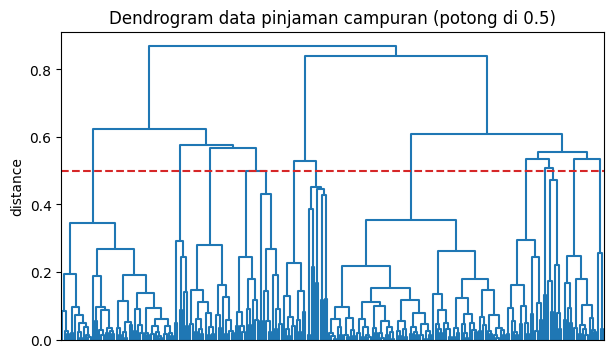

In [36]:
df = defaults[['dti', 'payment_inc_ratio', 'home_', 'purpose_']].sample(250, random_state=1)
df = df.assign(home_=df['home_'].astype(str), purpose_=df['purpose_'].astype(str))

d = gower_matrix(df)
Zg = linkage(squareform(d, checks=False), method='complete')

fig, ax = plt.subplots(figsize=(7, 4))
dendrogram(Zg, no_labels=True, color_threshold=0, ax=ax)
ax.set_ylabel('distance')
ax.axhline(0.5, color='C3', ls='--')
ax.set_title('Dendrogram data pinjaman campuran (potong di 0.5)')
plt.show()

Dendrogram dipotong secara horizontal di 0,5, lalu kita periksa isi tiap *cluster*. Menurut buku, subpohon tertentu terdiri seluruhnya dari pemilik rumah dengan tujuan pinjaman konsolidasi utang. Walaupun pemisahan setegas itu tidak berlaku untuk semua subpohon, hal ini menunjukkan bahwa **variabel kategorikal cenderung mengelompok bersama** dalam *cluster*.

In [37]:
cut = fcluster(Zg, t=0.5, criterion='distance')
df_c = df.assign(cluster=cut)
print('jumlah cluster pada potongan 0.5:', df_c.cluster.nunique())

# Seberapa murni tiap cluster terhadap variabel kategorikal?
summary = df_c.groupby('cluster').agg(
    ukuran=('dti', 'size'),
    home_dominan=('home_', lambda s: s.value_counts().index[0]),
    persen_home=('home_', lambda s: round(100 * s.value_counts(normalize=True).iloc[0])),
    purpose_dominan=('purpose_', lambda s: s.value_counts().index[0]),
    persen_purpose=('purpose_', lambda s: round(100 * s.value_counts(normalize=True).iloc[0])),
).sort_values('ukuran', ascending=False)
summary

jumlah cluster pada potongan 0.5: 12


,ukuran,home_dominan,persen_home,purpose_dominan,persen_purpose
cluster,,,,,
7,82,RENT,100,debt_consolidation,100
1,52,MORTGAGE,100,debt_consolidation,100
4,22,MORTGAGE,100,other,50
3,21,MORTGAGE,100,credit_card,100
8,17,RENT,100,other,100
11,16,RENT,100,credit_card,100
5,11,OWN,100,debt_consolidation,100
6,10,OWN,100,home_improvement,20
2,7,MORTGAGE,100,small_business,100


In [38]:
# Contoh isi satu cluster besar (setara df[labels(dnd_cut$lower[[1]]),] pada buku)
biggest = summary.index[0]
df_c[df_c.cluster == biggest].head(11)

,dti,payment_inc_ratio,home_,purpose_,cluster
20814,10.64,5.96356,RENT,debt_consolidation,7
4222,23.45,7.85068,RENT,debt_consolidation,7
4523,17.27,8.88000,RENT,debt_consolidation,7
12207,19.34,8.58722,RENT,debt_consolidation,7
4665,24.56,9.44936,RENT,debt_consolidation,7
14394,30.71,11.71290,RENT,debt_consolidation,7
13917,8.85,12.26330,RENT,debt_consolidation,7
221,23.36,6.70920,RENT,debt_consolidation,7
16697,5.26,2.64277,RENT,debt_consolidation,7
18283,16.74,10.84440,RENT,debt_consolidation,7


**Interpretasi hasil:**
- Pemotongan dendrogram pada jarak 0,5 menghasilkan 12 *cluster*. Hampir semuanya **murni terhadap variabel kategorikal**: untuk `home_`, seluruh *cluster* 100% sama, dan untuk `purpose_` sebagian besar *cluster* berisi satu tujuan pinjaman saja (misalnya 82 peminjam penyewa dengan tujuan konsolidasi utang, 52 peminjam KPR dengan konsolidasi utang).
- Seperti kata buku, pemisahan tegas tidak berlaku untuk semua *cluster* (misalnya *cluster* 4 hanya 50% murni terhadap `purpose_`), tetapi secara umum **variabel kategorikal cenderung mengelompok bersama** dalam *cluster*.
- Jarak Gower memperlakukan kategori sebagai 0 atau 1 sehingga beda kategori memberi kontribusi jarak yang besar dibanding variabel numerik yang sudah dibagi rentangnya.

### Teori: Masalah *clustering* data campuran

K-means dan PCA paling sesuai untuk **variabel kontinu**. Untuk data berukuran kecil, lebih baik memakai pengelompokan hierarkis dengan jarak Gower. Pada prinsipnya K-means dapat diterapkan pada data biner atau kategorikal dengan *one hot encoding*, tetapi dalam praktik **sulit**.

Jika *z-score* standar dipakai, **variabel biner akan mendominasi pembentukan *cluster***. Variabel 0/1 hanya memiliki dua nilai, sehingga K-means dapat memperoleh *within-cluster SS* kecil hanya dengan menetapkan semua record bernilai 0 atau 1 ke satu *cluster*. Akibatnya, *cluster* menjadi sekadar **proksi bagi tingkat-tingkat variabel faktor**.

Cara menghindarinya: **skalakan variabel biner agar variansnya lebih kecil** daripada variabel lain, atau untuk data yang sangat besar, terapkan *clustering* secara terpisah pada subset data dengan nilai kategorikal tertentu (misalnya terpisah untuk peminjam yang memiliki KPR, memiliki rumah sepenuhnya, dan menyewa).

### Kode: K-means dengan variabel biner

In [39]:
columns = ['dti', 'payment_inc_ratio', 'home_', 'pub_rec_zero']
df = pd.get_dummies(defaults[columns], dtype=float)

scaler = preprocessing.StandardScaler()
df0 = scaler.fit_transform(df * 1.0)

kmeans = KMeans(n_clusters=4, random_state=1, n_init=10).fit(df0)
centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_),
                       columns=df.columns)
centers['size'] = [Counter(kmeans.labels_)[i] for i in range(4)]
centers.round(2)

,dti,payment_inc_ratio,pub_rec_zero,home__MORTGAGE,home__OWN,home__RENT,size
0,17.46,8.42,1.00,1.00,-0.0,0.00,8857
1,16.99,9.11,1.00,0.00,-0.0,1.00,10138
2,17.20,9.27,0.92,0.00,1.0,0.00,1888
3,16.50,8.06,-0.00,0.52,-0.0,0.48,1788


**Interpretasi hasil:**
- Keempat *cluster* pada dasarnya hanya **mengikuti tingkat-tingkat variabel biner**: *cluster* 0 = semua `MORTGAGE`, *cluster* 1 = semua `RENT`, *cluster* 2 = semua `OWN`, dan *cluster* 3 = yang `pub_rec_zero` bernilai 0 (campuran MORTGAGE dan RENT).
- Nilai `dti` dan `payment_inc_ratio` hampir sama di semua *cluster* (±16,5 sampai 17,5 dan ±8 sampai 9). Artinya variabel numerik hampir tidak ikut membedakan *cluster*.
- Ini yang dimaksud buku: setelah standardisasi, variabel biner mendominasi karena K-means mudah mendapat SS kecil dengan memisahkan record berdasarkan nilai 0 atau 1. Hasilnya cocok dengan tabel pada buku.

### Tambahan: mengecilkan skala variabel biner
Buku menyarankan mengecilkan varians variabel biner. Berikut contoh sederhananya (**tambahan**, tidak ada kodenya di buku): setelah distandardisasi, kolom biner dikalikan 0,3 sehingga bobotnya dalam jarak berkurang.

In [40]:
binary_cols = [i for i, c in enumerate(df.columns) if c.startswith('home_') or c == 'pub_rec_zero']
df1 = df0.copy()
df1[:, binary_cols] = df1[:, binary_cols] * 0.3      # kecilkan pengaruh variabel biner

kmeans1 = KMeans(n_clusters=4, random_state=1, n_init=10).fit(df1)
centers1 = pd.DataFrame(scaler.inverse_transform(
    kmeans1.cluster_centers_ / np.where(np.isin(range(df.shape[1]), binary_cols), 0.3, 1.0)),
    columns=df.columns)
centers1['size'] = [Counter(kmeans1.labels_)[i] for i in range(4)]
centers1.round(2)

,dti,payment_inc_ratio,pub_rec_zero,home__MORTGAGE,home__OWN,home__RENT,size
0,9.23,5.37,0.90,0.43,0.08,0.49,6270
1,25.62,12.80,0.93,0.38,0.10,0.52,4820
2,21.54,5.82,0.91,0.50,0.07,0.43,6490
3,13.29,12.90,0.92,0.40,0.09,0.52,5091


**Interpretasi hasil (bagian tambahan):**
- Setelah pengaruh variabel biner dikecilkan (dikali 0,3), *cluster* tidak lagi sekadar proksi bagi `home_`: tiap *cluster* kini berisi campuran MORTGAGE, OWN, dan RENT dengan proporsi mirip (±38–50% MORTGAGE, ±43–52% RENT).
- *Cluster* sekarang dibedakan oleh variabel numerik: `dti` (±9, ±13, ±22, ±26) dan `payment_inc_ratio` (±5,4 sampai ±12,9). Ukuran *cluster* juga lebih seimbang (4.820 sampai 6.490).
- Angka pengali 0,3 hanyalah contoh. Dalam praktik, besarnya perlu disesuaikan dengan tujuan analisis.

---
## Summary dan Key Ideas (Rangkuman Chapter 7)

**Pemilihan metode**
- Untuk **reduksi dimensi data numerik**, alat utamanya adalah PCA atau K-means. Keduanya memerlukan **penskalaan data yang tepat** agar reduksi bermakna.
- Pada **data terstruktur dengan *cluster* yang terpisah jelas**, semua metode kemungkinan menghasilkan hasil yang mirip, dan masing-masing punya keunggulan:
  - **K-means**: dapat diskalakan ke data yang sangat besar dan mudah dipahami.
  - **Hierarchical clustering**: dapat diterapkan pada data campuran (numerik dan kategorikal) dan punya tampilan yang intuitif (dendrogram).
  - **Model-based clustering**: berlandaskan teori statistik dan lebih ketat dibanding metode heuristik.
- Untuk **data yang *noisy*** (seperti data pinjaman dan saham), ketiganya menghasilkan solusi yang **sangat berbeda**. Tidak ada aturan sederhana yang menentukan pilihan. Pada akhirnya, metode bergantung pada **ukuran data dan tujuan aplikasi**. Untuk data yang sangat besar, K-means adalah metode utama.

**Principal Components Analysis**
- Komponen utama adalah kombinasi linear dari variabel prediktor (hanya data numerik).
- Dihitung sehingga korelasi antarkomponen minimal, mengurangi redundansi.
- Sejumlah kecil komponen biasanya menjelaskan sebagian besar varians.
- Himpunan kecil komponen dapat menggantikan prediktor asli yang lebih banyak sehingga dimensi berkurang.
- *Correspondence analysis* adalah teknik serupa untuk data kategorikal, tetapi tidak berguna pada konteks *big data*.

**K-Means Clustering**
- Jumlah *cluster* $K$ ditentukan pengguna.
- Algoritma membentuk *cluster* dengan menetapkan record ke rata-rata *cluster* terdekat secara berulang sampai penetapan tidak berubah.
- Pertimbangan praktis biasanya menentukan pilihan $K$; tidak ada jumlah *cluster* optimal yang ditentukan secara statistik.

**Hierarchical Clustering**
- Dimulai dengan setiap record sebagai *cluster* sendiri, lalu *cluster* digabungkan secara progresif sampai semua record berada dalam satu *cluster* (algoritma aglomeratif).
- Riwayat penggabungan disimpan dan digambar, sehingga pengguna dapat melihat jumlah dan struktur *cluster* pada berbagai tahap tanpa menentukan jumlah *cluster* di awal.
- Jarak antar-*cluster* dihitung dengan beberapa cara, semuanya bertumpu pada himpunan jarak antarrecord.

**Model-Based Clustering**
- *Cluster* diasumsikan berasal dari proses pembangkitan data yang berbeda dengan distribusi probabilitas yang berbeda.
- Beberapa model dicocokkan, dengan jumlah distribusi (biasanya normal) yang berbeda-beda.
- Metode memilih model (dan jumlah *cluster*) yang cocok dengan data tanpa terlalu banyak parameter (menghindari *overfitting*).

**Scaling and Categorical Variables**
- Variabel dengan skala berbeda harus ditransformasi ke skala yang sama agar pengaruhnya pada algoritma tidak ditentukan oleh skalanya.
- Metode umum: normalisasi (standardisasi), yaitu mengurangi rata-rata dan membagi simpangan baku.
- Metode lain: jarak Gower, yang membawa semua variabel ke rentang 0 sampai 1 (sering dipakai pada data campuran numerik dan kategorikal).

## Referensi
- Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical Statistics for Data Scientists*, 2nd ed. O'Reilly. Chapter 7.
- Bro, R., Kjeldahl, K., Smilde, A. K., & Kiers, H. A. L. (2008). "Cross-Validation of Component Models: A Critical Look at Current Methods." *Analytical and Bioanalytical Chemistry* 390(5).
- Tibshirani, R., Walther, G., & Hastie, T. (2001). "Estimating the Number of Clusters in a Data Set via the Gap Statistic." *JRSS B* 63(2).
- Kode dan dataset sumber: https://github.com/gedeck/practical-statistics-for-data-scientists